# 00. src 공용 함수 사용법

`src/`의 공용 함수를 실제 데이터로 하나씩 실행해 보는 안내 노트북입니다. 함수가 무엇을 받고 무엇을 돌려주는지 보여 주는 것이 목적이고, 분석 결과가 아닙니다. 아래 수치(2024년 12월 한 달, 임시 기준값, 예시로 고른 반복 기준)를 분석 결론이나 발표 자료에 쓰지 않습니다.

- 위에서부터 순서대로 실행합니다. 처음에는 대여이력 zip을 parquet로 바꾸고 월별 이용정보를 읽느라 몇 분 걸립니다. 두 번째부터는 `data/interim/`에 만든 파일을 읽어 빠릅니다.
- 필요한 원본(`data/raw/`): `stations/`, `subway_stations/`, `usage_monthly/`, `new_members/`, `subway_ridership/`, `rent_history/`(2024년 zip)
- 노선 판별(`routes`)과 통근 지표(`metrics`)는 손으로 검산할 수 있는 작은 예시 데이터로 먼저 보여 주고, 그다음 실제 대여이력에 적용합니다.
- 함수마다 더 자세한 설명은 `src/*.py`의 docstring에 있습니다. 노트북에서 `help(loaders.load_stations)`나 `loaders.load_stations?`로 볼 수 있습니다.

| 절 | 모듈 | 하는 일 |
|---|---|---|
| 1 | (첫 셀) | 경로 설정, import, 그래프 설정 |
| 2 | `config` | 폴더 경로, 팀이 정하기 전 임시값, 출처 문구 |
| 3 | `calendar_kr` | 공휴일, 평일/주말·공휴일, 출근/퇴근 시간대, 기간 날 수 |
| 4 | `loaders` | 원본 읽기와 표기 통일, 대여이력 zip → 월별 parquet, 저장·캐시 |
| 5 | `geo` | 거리, 가장 가까운 지하철역, 역 인근 구분 |
| 6 | `routes` | 노선 × 시간대별 평일 출현일수, 반복 노선, 역방향 반복 (분석 ②) |
| 7 | `metrics` | 주말 기준선 통근 비중, 대여소 통근 지수 (② 교차 확인) |
| 8 | `viz` | 한글 폰트, 그래프·표 출처 표기, 숫자 축, 그림 저장 |

## 1. 첫 셀

모든 노트북의 첫 셀에 둡니다. `autoreload`를 켜 두면 `src/*.py`를 고쳤을 때 커널을 다시 시작하지 않아도 바로 반영됩니다. 노트북은 `notebooks/`에서 실행되므로 `..`(프로젝트 루트)를 경로에 넣어야 `from src import ...`가 됩니다.

In [1]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.append("..")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from src import calendar_kr, config, geo, loaders, metrics, routes, viz

viz.setup_plot()  # 한글 폰트, 마이너스 기호, 해상도, seaborn 스타일. 쓰인 폰트 이름을 돌려준다

'Malgun Gothic'

## 2. `config`: 경로, 임시값, 출처

- **경로**: 어느 PC에서 노트북을 열어도 프로젝트 루트를 기준으로 같은 폴더를 가리킵니다. `"../data/raw/..."` 대신 `config.DATA_RAW / "stations"`처럼 씁니다.
- **임시값**: README "팀이 정할 것" 표의 값입니다. 노트북에 `7, 8`이나 `300` 같은 숫자를 직접 적지 말고 이 상수를 씁니다. 팀이 값을 확정하면 `src/config.py` 한 곳만 고치면 되고, 다른 모듈 함수의 기본값도 모두 따라 바뀝니다.
- **`SOURCES`**: 그래프·표에 적을 출처 문구입니다. `viz.add_source(fig, "rent_history")`처럼 키로 씁니다.

In [3]:
for name in ("DATA_RAW", "DATA_INTERIM", "DATA_PROCESSED", "FIGURES"):
    print(f"{name:15} {getattr(config, name).relative_to(config.ROOT)}")

DATA_RAW        data\raw
DATA_INTERIM    data\interim
DATA_PROCESSED  data\processed
FIGURES         figures


In [4]:
print("출근 시간대:", config.COMMUTE_AM_HOURS, "/ 퇴근 시간대:", config.COMMUTE_PM_HOURS)
print("출퇴근 전체:", config.COMMUTE_HOURS)
print("역 인근:", config.NEAR_STATION_M, "m 이하 / 역에서 먼:", config.FAR_STATION_M, "m 초과")
print("추세·예측 기간:", config.TREND_PERIOD, "/ 상세 분석 연도:", config.DETAIL_YEAR)
config.provisional_note()  # 임시값으로 만든 그래프 아래에 붙일 안내 문구

출근 시간대: (7, 8) / 퇴근 시간대: (17, 18, 19)
출퇴근 전체: (7, 8, 17, 18, 19)
역 인근: 300 m 이하 / 역에서 먼: 1000 m 초과
추세·예측 기간: ('2022-01-01', '2026-06-30') / 상세 분석 연도: 2024


'임시 기준: 출퇴근 시간대 07~09시·17~20시, 역 인근 300m, 역에서 먼 대여소 1km 초과'

In [5]:
pd.Series(config.SOURCES, name="출처 문구").to_frame()

,출처 문구
usage_monthly,서울 열린데이터광장 「서울시 공공자전거 따릉이 이용정보(월별)」(OA-15248)
usage_hourly,서울 열린데이터광장 「서울시 공공자전거 이용정보(시간대별)」(OA-15245)
new_members,서울 열린데이터광장 「서울시 공공자전거 따릉이 신규가입자 정보(일별)」(OA-15243)
rent_history,서울 열린데이터광장 「서울시 공공자전거 따릉이 대여이력 정보」(OA-15182)
availability,서울 열린데이터광장 「서울시 대여소별 공공자전거 따릉이 대여가능 수량」(OA-22382)
stations,서울 열린데이터광장 「서울시 공공자전거 따릉이 대여소 정보」(OA-13252)
subway_ridership,서울 열린데이터광장 「서울교통공사 역별 일별 시간대별 승하차인원」(OA-12921)
subway_stations,서울 열린데이터광장 「서울시 역사마스터 정보」(OA-21232)
asos,기상청 기상자료개방포털 「종관기상관측(ASOS)」 서울 지점
holidays,"우주항공청 월력요항(관보), 관공서의 공휴일에 관한 규정"


## 3. `calendar_kr`: 공휴일, 평일/주말·공휴일, 시간대

2022~2026년 공휴일(대체공휴일, 임시공휴일, 선거일 포함)이 들어 있습니다. 공휴일은 주말과 같은 **"주말·공휴일"**로 분류합니다. 그 밖의 연도를 넣으면 토·일요일만 휴일로 잡힌다는 경고가 나옵니다.

| 함수 | 하는 일 |
|---|---|
| `period_start(v)`, `period_end(v)` | `"2024"`, `"2024-06"`을 그 기간의 첫날·마지막 날로 바꾼다 |
| `is_offday(dates)` | 토·일요일이나 공휴일이면 True |
| `day_kind(dates)` | `"평일"` / `"주말·공휴일"` (순서 있는 범주형) |
| `time_band(hours)` | 시간(0~23)을 `"출근"` / `"퇴근"` / `"그 외"`로 나눈다 (기준은 `config` 임시값) |
| `calendar_table(start, end)` | 하루 한 줄짜리 달력: 날짜, 요일, 공휴일명, 일구분 |
| `count_days(start, end)` | 기간 안의 평일 수와 주말·공휴일 수 (하루 평균을 낼 때 분모) |
| `add_time_columns(df, col)` | 일시 컬럼에서 날짜·연도·월·요일·시간대·일구분·시간구분 컬럼을 만들어 붙인 복사본 |

모든 함수에 `labor_day_as_holiday` 인자가 있습니다. 2025년까지 5월 1일(근로자의 날)은 공휴일이 아니어서 기본값(False)은 평일로 봅니다. 출퇴근 분석에서 휴일로 볼지는 이 인자로 고릅니다.

In [6]:
# 달로 주면 그 달 전체, 해로 주면 그 해 전체를 뜻한다
print(calendar_kr.period_start("2024-06"), "~", calendar_kr.period_end("2024-06"))
print(calendar_kr.period_start("2024"), "~", calendar_kr.period_end("2024"))
print(calendar_kr.period_end("2024-06-15"))  # 날짜로 주면 그날

2024-06-01 00:00:00 ~ 2024-06-30 00:00:00
2024-01-01 00:00:00 ~ 2024-12-31 00:00:00
2024-06-15 00:00:00


In [7]:
days = ["2024-05-01", "2024-05-06", "2024-05-07", "2026-05-01"]
pd.DataFrame(
    {
        "날짜": days,
        "is_offday": calendar_kr.is_offday(days),
        "day_kind": calendar_kr.day_kind(days),
        "근로자의 날을 휴일로": calendar_kr.day_kind(days, labor_day_as_holiday=True),
    }
)
# 2024-05-06은 대체공휴일(어린이날), 2026-05-01은 노동절(2026년부터 공휴일)

,날짜,is_offday,day_kind,근로자의 날을 휴일로
0,2024-05-01,False,평일,주말·공휴일
1,2024-05-06,True,주말·공휴일,주말·공휴일
2,2024-05-07,False,평일,평일
3,2026-05-01,True,주말·공휴일,주말·공휴일


In [8]:
hours = [6, 7, 8, 9, 12, 17, 19, 20]
pd.DataFrame({"시간대": hours, "time_band": calendar_kr.time_band(hours)}).T
# 시간대 h는 h:00~h:59를 뜻한다. 7, 8 → 07:00~08:59 출근 / 17, 18, 19 → 17:00~19:59 퇴근

,0,1,2,3,4,5,6,7
시간대,6,7,8,9,12,17,19,20
time_band,그 외,출근,출근,그 외,그 외,퇴근,퇴근,그 외


In [9]:
calendar_kr.calendar_table("2024-09-14", "2024-09-19")  # 2024년 추석 연휴

,날짜,요일,공휴일명,일구분
0,2024-09-14,토,NaN,주말·공휴일
1,2024-09-15,일,NaN,주말·공휴일
2,2024-09-16,월,추석 연휴,주말·공휴일
3,2024-09-17,화,추석,주말·공휴일
4,2024-09-18,수,추석 연휴,주말·공휴일
5,2024-09-19,목,NaN,평일


In [10]:
pd.DataFrame(
    {
        "2024-12 한 달": calendar_kr.count_days("2024-12", "2024-12"),
        "2024년 한 해": calendar_kr.count_days("2024", "2024"),
    }
)

,2024-12 한 달,2024년 한 해
일구분,,
평일,21,246
주말·공휴일,10,120


In [11]:
toy = pd.DataFrame(
    {
        "대여일시": pd.to_datetime(
            ["2024-05-03 08:15", "2024-05-05 18:40", "2024-05-06 07:59", "2024-05-07 13:05"]
        )
    }
)
calendar_kr.add_time_columns(toy, "대여일시")
# 2024-05-06 07:59는 출근 시간대지만 대체공휴일이라 일구분은 주말·공휴일이다

,대여일시,날짜,연도,월,요일,시간대,일구분,시간구분
0,2024-05-03 08:15:00,2024-05-03,2024,5,금,8,평일,출근
1,2024-05-05 18:40:00,2024-05-05,2024,5,일,18,주말·공휴일,퇴근
2,2024-05-06 07:59:00,2024-05-06,2024,5,월,7,주말·공휴일,출근
3,2024-05-07 13:05:00,2024-05-07,2024,5,화,13,평일,그 외


In [12]:
# 반납일시처럼 다른 컬럼에 붙일 때는 prefix로 컬럼 이름을 구분한다
calendar_kr.add_time_columns(
    toy.rename(columns={"대여일시": "반납일시"}), "반납일시", prefix="반납"
).columns.tolist()

['반납일시', '반납날짜', '반납연도', '반납월', '반납요일', '반납시간대', '반납일구분', '반납시간구분']

## 4. `loaders`: 원본 읽기

원본(`data/raw/`)은 받은 그대로 두고, 읽을 때만 인코딩·컬럼명·값 표기를 맞춥니다. 원본에 있는 이상값(생년 0·2099, 센터·정비 대여소 코드 등)은 지우지 않고 그대로 두니, 분석에서 기준을 정해 거릅니다. 함수마다 docstring에 확인한 이상값을 적어 두었습니다.

### 4-1. 표기 통일

| 함수 | 하는 일 |
|---|---|
| `read_table(path)` | csv든 xlsx든 내용을 보고 읽는다. 인코딩(cp949, UTF-8)도 알아서 고른다. 확장자만 .csv인 엑셀 파일도 읽는다 |
| `normalize_station_id(ids)` | 대여소번호를 5자리 문자열로: `102`, `"102.0"` → `"00102"` |
| `normalize_sex(values)` | 성별을 `"M"`/`"F"`로. 빈칸과 `\N`은 결측 |
| `normalize_age(values)` | 연령대 `"10대"` → `"~10대"`, `AGE_ORDER` 순서의 범주형 |

데이터셋별 로더가 안에서 이 함수들을 부르므로, 보통은 직접 쓸 일이 없습니다.

In [13]:
pd.DataFrame(
    {
        "원본 대여소번호": ["102", "00102", "102.0", "", "3"],
        "normalize_station_id": loaders.normalize_station_id(
            pd.Series(["102", "00102", "102.0", "", "3"])
        ),
        "원본 성별": ["m", "F", "\\N", "", "M"],
        "normalize_sex": loaders.normalize_sex(pd.Series(["m", "F", "\\N", "", "M"])),
    }
)

,원본 대여소번호,normalize_station_id,원본 성별,normalize_sex
0,102,00102,m,M
1,00102,00102,F,F
2,102.0,00102,\N,<NA>
3,,<NA>,,<NA>
4,3,00003,M,M


In [14]:
loaders.normalize_age(pd.Series(["10대", "~10대", "20대", "70대이상"]))

0     ~10대
1     ~10대
2      20대
3    70대이상
dtype: category
Categories (8, str): ['~10대' < '20대' < '30대' < '40대' < '50대' < '60대' < '70대이상' < '기타']

### 4-2. 데이터셋별 로더

| 함수 | 데이터 | 메모 |
|---|---|---|
| `list_station_snapshots()` | 대여소 정보 파일 목록 | 기준 시점(`"2024-06"` 등) 순 |
| `load_stations(asof)` | 대여소 목록 한 시점 | 생략하면 가장 최근 시점 |
| `load_stations_union()` | 모든 시점을 합친 대여소 목록 | 중간에 없어진 대여소도 남는다. 대여이력에 좌표를 붙일 때 쓴다 |
| `load_subway_stations(lines)` | 지하철역 좌표(역사마스터) | **공개 저장소에 원본·가공본을 올리지 않는다** |
| `load_usage_monthly(start, end)` | 월별 이용정보 | 이용권을 `이용권_대분류`로 묶고 `정기권여부`를 붙인다 |
| `load_new_members(start, end)` | 일별 신규가입자 | 같은 날이 여러 줄로 나뉜 경우가 있어 집계는 반드시 합계로 |
| `load_subway_ridership(years, long)` | 역별·일별·시간대별 승하차 | 1~8호선 서울교통공사 관할만 |

In [15]:
loaders.list_station_snapshots().keys()

dict_keys(['2024-06', '2024-12', '2025-06', '2025-12'])

In [16]:
stations = loaders.load_stations("2024-12")
print(stations.shape)
stations.head(3)

(2766, 12)


,대여소번호,대여소명,자치구,상세주소,위도,경도,설치일시,LCD거치대수,QR거치대수,거치대수,운영방식,기준시점
0,00301,경복궁역 7번출구 앞,종로구,서울특별시 종로구 사직로 지하130 경복궁역 7번출구 앞,37.575794,126.971451,2015-10-07 12:03:46,<NA>,20,20,QR,2024-12
1,00302,경복궁역 4번출구 뒤,종로구,서울특별시 종로구 사직로 지하130 경복궁역 4번출구 뒤,37.575947,126.974060,2015-10-07 12:04:22,<NA>,12,12,QR,2024-12
2,00303,광화문역 1번출구 앞,종로구,서울특별시 종로구 세종대로 지하189 세종로공원,37.571770,126.974663,2015-10-07 00:00:00,<NA>,8,8,QR,2024-12


In [17]:
stations_all = loaders.load_stations_union()
print(stations_all.shape)
# 처음확인·마지막확인은 받은 파일 시점 기준이다(실제 설치·폐쇄일이 아님)
stations_all.groupby(["처음확인", "마지막확인"]).size().rename("대여소 수").to_frame()

(2880, 14)


대여소 수
처음확인    마지막확인         
2024-06 2024-06     44
        2024-12     12
        2025-06     24
        2025-12   2683
2024-12 2024-12      1
        2025-12     47
2025-06 2025-12     26
2025-12 2025-12     43

역사마스터는 다운로드 권한을 받아 쓰는 자료라 원본과 좌표를 출력하거나 `data/processed/`에 저장하지 않습니다. 이 노트북도 개수만 보이고, 5절에서 대여소별 "가장 가까운 역·거리" 같은 결과값만 씁니다.

서울교통공사 노선 말고 광역철도 등도 들어 있으니, 특정 노선만 쓰려면 `lines=["1호선", "2호선"]`처럼 거릅니다.

In [18]:
subway = loaders.load_subway_stations()
print(f"{len(subway)}줄 (환승역은 호선마다 한 줄), 노선 {subway['호선'].nunique()}개")
subway["호선"].value_counts().head(10).rename("역 수").to_frame()

784줄 (환승역은 호선마다 한 줄), 노선 39개


,역 수
호선,
5호선,56
7호선,53
2호선,50
6호선,39
경부선,39
분당선,35
3호선,34
인천1호선,33
경원선,32


월별 이용정보는 파일이 많아 한 번 읽는 데 시간이 걸립니다. 노트북에서는 `loaders.cached()`로 감싸 두면 처음 한 번만 원본을 읽고, 그다음부터는 `data/interim/usage_monthly.parquet`를 읽습니다(4-4 참고).

In [19]:
usage = loaders.cached("usage_monthly", loaders.load_usage_monthly)
print(usage.shape, usage["대여월"].min().date(), "~", usage["대여월"].max().date())
usage.head(3)

(5749458, 13) 2022-01-01 ~ 2026-06-01


,대여월,대여소번호,대여소명,이용권,이용권_대분류,정기권여부,성별,연령대,이용건수,운동량,탄소량,이동거리_m,이용시간_분
0,2022-01-01,00003,중랑센터,일일(회원),일일권,False,M,50대,1,0.00,0.00,0.00,10.0
1,2022-01-01,00003,중랑센터,정기,정기권,True,NaN,50대,3,62.44,0.51,2190.00,24.0
2,2022-01-01,00003,중랑센터,정기,정기권,True,M,40대,5,106.18,0.73,3154.57,49.0


In [20]:
# 예: 연도별 이용건수와 정기권 비중
yearly = usage.groupby(usage["대여월"].dt.year.rename("연도")).agg(
    이용건수=("이용건수", "sum"),
    정기권_이용건수=("이용건수", lambda s: s[usage.loc[s.index, "정기권여부"]].sum()),
)
yearly["정기권비중"] = yearly["정기권_이용건수"] / yearly["이용건수"]
yearly
# 2026년은 1~6월만 있다

,이용건수,정기권_이용건수,정기권비중
연도,,,
2022,40950756,32907734,0.803593
2023,44904665,37327233,0.831255
2024,43849559,36467655,0.831654
2025,37373054,31168924,0.833995
2026,17978894,14456079,0.804058


In [21]:
# 연령대 코드 'AGE_009' 경고가 나온다. 연령대 표에 없는 값이라 지우지 않고 맨 뒤 범주로 둔 것이다
members = loaders.load_new_members("2024-01", "2024-12")
print(members.shape)
members.head(3)

(5529, 5)


D:\dev\projects\bigdata-final\notebooks\..\src\loaders.py:302: UserWarning: 연령대 표에 없는 값: ['AGE_009'] (그대로 둠)
  "연령대": normalize_age(df["연령대"]),


,가입일자,사용자코드,연령대,성별,가입건수
0,2024-01-01,회원-내국인,~10대,F,52
1,2024-01-01,회원-내국인,~10대,M,103
2,2024-01-01,회원-내국인,20대,F,98


In [22]:
# 같은 날·연령대·성별이 여러 줄로 나뉜 경우가 있으니 항상 합계로 모은다
members.groupby(members["가입일자"].dt.month)["가입건수"].sum().rename_axis("2024년 월").to_frame().T

2024년 월,1,2,3,4,5,6,7,8,9,10,11,12
가입건수,15591,41162,56467,82167,68164,54367,31388,36282,50381,54999,28417,12677


In [23]:
ride = loaders.load_subway_ridership(years=[2024])
print(ride.shape)
ride.head(3)
# 시간대 5는 "06시 이전", 24는 "24시 이후", 나머지 h는 h:00~h:59

(3988200, 8)


,날짜,호선,역번호,역사_ID,역명,구분,시간대,인원
0,2024-01-01,1호선,150,0150,서울역,승차,5,383
1,2024-01-01,1호선,150,0150,서울역,승차,6,257
2,2024-01-01,1호선,150,0150,서울역,승차,7,308


### 4-3. 대여이력: zip → 월별 parquet

대여이력(한 해 csv 약 7GB)은 한 번에 읽으면 메모리가 부족합니다. zip을 풀지 않고 청크로 읽어 `data/interim/rent_history/2024-12.parquet`처럼 달마다 저장한 뒤, 그 parquet에서 필요한 달·컬럼만 읽습니다.

| 함수 | 하는 일 |
|---|---|
| `available_months("rent_history", 2024)` | 그 해 zip에 들어 있는 달 목록 |
| `rent_history_to_parquet(year, months)` | 월별 parquet로 바꾼다. 이미 만든 달은 건너뛴다(컬럼을 바꿨으면 `overwrite=True`) |
| `load_rent_history(months, columns, filters)` | 만든 parquet를 읽는다 |
| `iter_rent_history(year, months)` | parquet를 거치지 않고 청크로 바로 읽는다 |

대여가능 수량도 같은 구조입니다: `availability_to_parquet()`, `load_availability()`, `iter_availability()`.

In [24]:
loaders.available_months("rent_history", 2024)

['2024-01',
 '2024-02',
 '2024-03',
 '2024-04',
 '2024-05',
 '2024-06',
 '2024-07',
 '2024-08',
 '2024-09',
 '2024-10',
 '2024-11',
 '2024-12']

In [25]:
# 처음 실행하면 2024-12 한 달을 parquet로 만든다(수십 초). 이미 있으면 건너뛰고 빈 목록을 돌려준다.
# 1년 전체는 loaders.rent_history_to_parquet(2024)
made = loaders.rent_history_to_parquet(2024, months=["2024-12"])
[p.name for p in made]

  이미 있어서 건너뜀: 2024-12 (다시 만들려면 overwrite=True)


[]

In [26]:
rent = loaders.load_rent_history(months=["2024-12"])
print(f"{len(rent):,}건", list(rent.columns))
rent[["대여일시", "대여소번호", "반납일시", "반납대여소번호", "이용시간_분", "이용거리_m"]].head(3)

2,277,919건 ['대여일시', '대여소번호', '반납일시', '반납대여소번호', '이용시간_분', '이용거리_m', '생년', '성별', '이용자종류', '자전거구분']


,대여일시,대여소번호,반납일시,반납대여소번호,이용시간_분,이용거리_m
0,2024-12-01 00:00:13,00228,2024-12-01 00:02:41,04560,2,625.1
1,2024-12-01 00:01:22,01192,2024-12-01 00:03:31,02732,2,0.0
2,2024-12-01 00:00:24,00245,2024-12-01 00:04:11,00280,3,890.0


In [27]:
# 필요한 컬럼만, 조건에 맞는 행만 읽을 수도 있다 (filters는 pyarrow 형식)
long_rides = loaders.load_rent_history(
    months=["2024-12"],
    columns=["대여일시", "대여소번호", "이용시간_분"],
    filters=[("이용시간_분", ">=", 60)],
)
print(f"60분 이상 이용: {len(long_rides):,}건")

60분 이상 이용: 134,275건


### 4-4. 저장과 캐시

| 함수 | 하는 일 |
|---|---|
| `save_parquet(df, name, where="processed")` | `data/processed/`(기본, **git에 올라감**) 또는 `where="interim"`(git 제외)에 저장 |
| `read_parquet(name, where)` | 저장한 파일 읽기. `columns=`, `filters=`를 넘길 수 있다 |
| `cached(name, build, refresh=False)` | `data/interim/<name>.parquet`가 있으면 읽고, 없으면 `build()`로 만들어 저장 |

`cached`는 이름으로만 파일을 찾습니다. 인자를 바꿔 부를 때는 이름도 바꿉니다. 원본이 바뀌었으면 `refresh=True`로 다시 만듭니다.

```python
h1 = loaders.cached("usage_2024h1", lambda: loaders.load_usage_monthly("2024-01", "2024-06"))
```

In [28]:
# 이 노트북의 예시는 git에 올라가지 않도록 interim에 저장한다
path = loaders.save_parquet(yearly.reset_index(), "00_guide_yearly", where="interim")
print(path.relative_to(config.ROOT))
loaders.read_parquet("00_guide_yearly", where="interim")

data\interim\00_guide_yearly.parquet


,연도,이용건수,정기권_이용건수,정기권비중
0,2022,40950756,32907734,0.803593
1,2023,44904665,37327233,0.831255
2,2024,43849559,36467655,0.831654
3,2025,37373054,31168924,0.833995
4,2026,17978894,14456079,0.804058


## 5. `geo`: 거리, 가장 가까운 지하철역

| 함수 | 하는 일 |
|---|---|
| `haversine_m(lat1, lon1, lat2, lon2)` | 두 지점 사이 거리(m). 배열끼리 넣으면 원소별로 계산 |
| `nearest(points, targets, k)` | 각 지점에서 가장 가까운 대상 k개와 거리 |
| `classify_distance(dist_m)` | 거리를 `"역 인근"`(≤ 300m) / `"중간"` / `"역에서 먼"`(> 1km)으로 (기준은 `config` 임시값) |
| `add_station_proximity(stations, subway)` | 대여소 표에 최근접역_ID, 최근접역, 최근접역_호선, 역거리_m, 역근접구분을 붙인다 |

거리는 역 출입구가 아니라 역사마스터의 역 대표 좌표 기준입니다. 환승역은 호선마다 좌표가 따로 있어, 그중 가장 가까운 좌표까지의 거리가 됩니다.

In [29]:
a, b = stations.iloc[0], stations.iloc[2]
d = geo.haversine_m(a["위도"], a["경도"], b["위도"], b["경도"])
print(f"{a['대여소명']} ↔ {b['대여소명']}: {float(d):.0f}m")

경복궁역 7번출구 앞 ↔ 광화문역 1번출구 앞: 530m


In [30]:
geo.classify_distance(pd.Series([120.0, 300.0, 450.0, 1000.0, 1500.0])).to_frame().T
# 경계값은 아래 구간에 들어간다: 300m → 역 인근, 1000m → 중간

,0,1,2,3,4
역근접구분,역 인근,역 인근,중간,중간,역에서 먼


In [31]:
bikes = geo.add_station_proximity(stations_all, subway)
bikes[["대여소번호", "대여소명", "최근접역", "최근접역_호선", "역거리_m", "역근접구분"]].head()

,대여소번호,대여소명,최근접역,최근접역_호선,역거리_m,역근접구분
0,00462,신영동삼거리(북악터널방향),홍제,3호선,2277.8,역에서 먼
1,03423,현대그룹(본사),종로5가,1호선,555.4,중간
2,00484,도동삼거리,회현(남대문시장),4호선,272.8,역 인근
3,00803,한남초교 앞 보도육교,한강진,6호선,266.9,역 인근
4,00812,용산전쟁기념관,삼각지,6호선,329.2,중간


In [32]:
bikes["역근접구분"].value_counts(sort=False).rename("대여소 수").to_frame().T

역근접구분,역 인근,중간,역에서 먼
대여소 수,1037,1573,270


In [33]:
# 가까운 역 두 개 (k>1이면 컬럼 이름 뒤에 _1, _2가 붙는다)
geo.nearest(stations.head(3), subway, k=2).round(1)

,역사_ID_1,역사명_1,호선_1,거리_m_1,역사_ID_2,역사명_2,호선_2,거리_m_2
0,0317,경복궁(정부서울청사),3호선,183.3,2534,광화문(세종문화회관),5호선,692.4
1,0317,경복궁(정부서울청사),3호선,51.0,2534,광화문(세종문화회관),5호선,562.9
2,2534,광화문(세종문화회관),5호선,222.6,0317,경복궁(정부서울청사),3호선,455.0


## 6. `routes`: 반복 노선 찾기 (분석 ②)

노선은 "대여 대여소 → 반납 대여소"입니다. 대여 시각 1시간 단위 시간대마다, 그 노선이 평일 며칠에 나타났는지(**평일출현일수**)를 셉니다. 하루에 여러 번 나와도 하루로 셉니다.

| 함수 | 하는 일 |
|---|---|
| `route_stats(rent)` | 대여 한 건이 한 줄인 표에서 노선 × 시간대 통계를 만든다 |
| `build_route_stats(months)` | 월별 parquet를 한 달씩 읽어 합친다(1년도 메모리 부담이 적다). `attrs`에 평일·휴일 날 수를 남긴다 |
| `flag_repeated_routes(stats, min_weekdays, hours)` | 출퇴근 시간대에 평일 `min_weekdays`일 이상 나타난 노선이면 True. 왕복(대여소 = 반납소)은 기본으로 뺀다 |
| `mark_reverse_pairs(stats, flag)` | 아침 A → B 반복 노선 중 저녁 B → A도 반복되는 것(그 반대도)에 True |

반복 기준(`min_weekdays`)은 팀이 분포를 보고 정할 값이라 기본값이 없습니다.

### 6-1. 작은 예시

결과를 손으로 확인할 수 있게 가짜 기록 11건을 만듭니다.

- A(00101) → B(00202): 평일 08시, 3일(5/7에는 두 번)
- B → A: 평일 18시, 3일
- C(00303) → C: 평일 08시 왕복, 3일
- D(00404) → E(00505): 토요일 14시, 한 번

In [34]:
rows = []
for d in ["2024-05-07", "2024-05-08", "2024-05-09"]:  # 화·수·목
    rows += [
        (f"{d} 08:10", "00101", "00202"),  # A → B (아침)
        (f"{d} 18:20", "00202", "00101"),  # B → A (저녁)
        (f"{d} 08:30", "00303", "00303"),  # C → C (왕복)
    ]
rows += [
    ("2024-05-07 08:40", "00101", "00202"),  # 같은 날 A → B 한 번 더
    ("2024-05-11 14:00", "00404", "00505"),  # 토요일 D → E
]
toy_rent = pd.DataFrame(rows, columns=["대여일시", "대여소번호", "반납대여소번호"])
toy_rent["대여일시"] = pd.to_datetime(toy_rent["대여일시"])

toy_stats = routes.route_stats(toy_rent)
toy_stats
# A → B는 평일건수 4, 평일출현일수 3 (같은 날 두 번은 하루로 센다)

,시간대,대여소번호,반납대여소번호,평일건수,평일출현일수,휴일건수,휴일출현일수,왕복
0,8,00101,00202,4,3,0,0,False
1,8,00303,00303,3,3,0,0,True
2,14,00404,00505,0,0,1,1,False
3,18,00202,00101,3,3,0,0,False


In [35]:
toy_flag = routes.flag_repeated_routes(toy_stats, min_weekdays=3)
toy_stats.assign(
    반복노선=toy_flag,
    역방향반복=routes.mark_reverse_pairs(toy_stats, toy_flag),
)
# C → C는 왕복이라, D → E는 14시(출퇴근 시간대 밖)라 빠진다.
# A → B(아침)와 B → A(저녁)는 서로 역방향으로 반복되므로 둘 다 역방향반복

,시간대,대여소번호,반납대여소번호,평일건수,평일출현일수,휴일건수,휴일출현일수,왕복,반복노선,역방향반복
0,8,00101,00202,4,3,0,0,False,True,True
1,8,00303,00303,3,3,0,0,True,False,False
2,14,00404,00505,0,0,1,1,False,False,False
3,18,00202,00101,3,3,0,0,False,True,True


### 6-2. 실제 대여이력 (2024년 12월)

1년 전체는 `routes.build_route_stats([f"2024-{m:02d}" for m in range(1, 13)])`입니다. 여기서는 한 달만 봅니다.

In [36]:
stats = routes.build_route_stats(["2024-12"])
print(stats.attrs)  # 고른 달들의 평일·휴일 날 수 (출현 비율의 분모). parquet로 저장하면 사라진다
stats.head()

  2024-12: 대여 2,277,919건, 누적 노선×시간대 914,502개
{'평일일수': 21, '휴일일수': 10}


,시간대,대여소번호,반납대여소번호,평일건수,평일출현일수,휴일건수,휴일출현일수,왕복
0,0,00102,00104,1,1,1,1,False
1,0,00102,00105,1,1,0,0,False
2,0,00102,00107,1,1,0,0,False
3,0,00102,00115,1,1,0,0,False
4,0,00102,00118,0,0,1,1,False


In [37]:
# 반복 기준을 정하려면 먼저 분포를 본다: 출퇴근 시간대, 왕복 제외
commute = stats[stats["시간대"].isin(config.COMMUTE_HOURS) & ~stats["왕복"]]
dist = commute.groupby("평일출현일수").agg(
    노선수=("평일건수", "size"), 평일건수=("평일건수", "sum")
)
# n일 이상 나타난 노선들이 출퇴근 시간대 평일 이용의 몇 %를 차지하는지
dist["n일 이상 건수비중"] = dist["평일건수"][::-1].cumsum()[::-1] / dist["평일건수"].sum()
dist.style.format({"노선수": "{:,}", "평일건수": "{:,}", "n일 이상 건수비중": "{:.1%}"})

,노선수,평일건수,n일 이상 건수비중
평일출현일수,,,
0,"36,119",0,100.0%
1,"122,555","126,217",100.0%
2,"34,564","71,578",82.0%
3,"16,643","52,203",71.8%
4,"9,905","41,849",64.4%
5,"6,684","35,676",58.4%
6,"4,818","31,063",53.3%
7,"3,681","28,117",48.9%
8,"2,919","25,659",44.9%


In [38]:
MIN_WEEKDAYS = 10  # 예시값. 12월 평일 21일 중 10일 이상. 팀이 분포를 보고 정한다

stats["반복노선"] = routes.flag_repeated_routes(stats, min_weekdays=MIN_WEEKDAYS)
stats["역방향반복"] = routes.mark_reverse_pairs(stats, stats["반복노선"])

repeated = stats[stats["반복노선"]]
print(f"반복 노선(노선 × 시간대): {len(repeated):,}개, 그중 역방향 반복 {stats['역방향반복'].sum():,}개")
print(
    "출퇴근 시간대 평일 이용 중 반복 노선 비중:",
    f"{repeated['평일건수'].sum() / commute['평일건수'].sum():.1%}",
)

반복 노선(노선 × 시간대): 12,477개, 그중 역방향 반복 5,159개
출퇴근 시간대 평일 이용 중 반복 노선 비중: 37.8%


In [39]:
# 대여소 이름은 대여소 목록에서 붙인다
names = stations_all.set_index("대여소번호")["대여소명"]
top = repeated.nlargest(10, "평일건수").copy()
top.insert(2, "대여소명", top["대여소번호"].astype("string").map(names))
top.insert(4, "반납대여소명", top["반납대여소번호"].astype("string").map(names))
top.drop(columns=["왕복", "반복노선"])

,시간대,대여소번호,대여소명,반납대여소번호,반납대여소명,평일건수,평일출현일수,휴일건수,휴일출현일수,역방향반복
160806,8,02701,마곡나루역 5번출구 뒤편,05096,LG사이언스파크 E14동,475,21,0,0,True
712547,18,05096,LG사이언스파크 E14동,02728,마곡나루역 3번 출구,335,21,0,0,True
112913,7,00781,신정보도육교 아래,04543,오목교역 6번 출구,315,21,8,7,True
161546,8,02728,마곡나루역 3번 출구,05096,LG사이언스파크 E14동,304,21,1,1,True
641761,17,05089,LG사이언스파크 E10동,02728,마곡나루역 3번 출구,303,21,1,1,True
124281,7,02733,마곡13단지 정문 앞,05052,마곡역 7번출구,289,21,6,4,True
143965,8,00781,신정보도육교 아래,04543,오목교역 6번 출구,236,21,15,8,True
128985,7,04108,답십리파크자이아파트 앞,04137,답십리역 4번출구,221,21,5,3,True
699167,18,03934,철도교통관제센터 정문 앞,01908,해원리바파크 육교 밑,217,21,58,10,True
642003,17,05096,LG사이언스파크 E14동,02728,마곡나루역 3번 출구,214,21,2,2,True


## 7. `metrics`: 주말 기준선 통근 지표 (② 교차 확인)

노선 반복과는 다른 방법으로 출퇴근 수요를 어림해, 6절 결과와 비교하는 데 씁니다.

```text
출퇴근 초과 이용_h = 평일 하루 평균_h − 주말·공휴일 하루 평균_h
통근 비중 = Σ(출퇴근 시간대) max(초과 이용_h, 0) / Σ(전 시간대) 평일 하루 평균_h
```

평일 여가 이용을 주말 수준으로 가정한 값이라, 실제 통근량보다 작게 나오는 하한(보수적 추정)입니다.

| 함수 | 하는 일 |
|---|---|
| `hourly_daily_mean(df, count_col, by, start, end)` | 시간대별 하루 평균을 평일과 주말·공휴일로 나눠 구한다. 이용이 0건인 날도 분모에 들어간다(`groupby().mean()`과 다름) |
| `commute_share(hourly, by)` | 위 결과로 통근 비중을 구한다 |
| `station_commute_index(df, min_count)` | 대여소 통근 지수 = 평일 중 출퇴근 시간대 비중 − 주말·공휴일 중 같은 시간대 비중 |

입력은 `날짜`, `시간대` 컬럼이 있는 표입니다(`calendar_kr.add_time_columns()`로 만든다). 대여이력처럼 한 줄이 한 건이면 `count_col=None`(기본), 집계표처럼 건수 컬럼이 있으면 `count_col="이용건수"`를 줍니다.

### 7-1. 작은 예시

2024-05-06(월, 대체공휴일) ~ 05-12(일), 평일 4일·주말·공휴일 3일입니다. 대여소 00101은 평일 08시·18시에 10건, 그 밖에는 시간마다 2건입니다. 00202는 늘 시간마다 2건입니다.

In [40]:
rows = []
for d in pd.date_range("2024-05-06", "2024-05-12"):
    weekday = calendar_kr.day_kind([d])[0] == calendar_kr.WEEKDAY
    for h in range(24):
        rows.append((d, h, "00101", 10 if weekday and h in (8, 18) else 2))
        rows.append((d, h, "00202", 2))
toy_hourly = pd.DataFrame(rows, columns=["날짜", "시간대", "대여소번호", "이용건수"])

toy_mean = metrics.hourly_daily_mean(toy_hourly, count_col="이용건수", by="대여소번호")
toy_mean[toy_mean["시간대"].isin([8, 12])]

,대여소번호,일구분,시간대,합계,일수,하루평균
8,00101,평일,8,40.0,4,10.0
12,00101,평일,12,8.0,4,2.0
32,00101,주말·공휴일,8,6.0,3,2.0
36,00101,주말·공휴일,12,6.0,3,2.0
56,00202,평일,8,8.0,4,2.0
60,00202,평일,12,8.0,4,2.0
80,00202,주말·공휴일,8,6.0,3,2.0
84,00202,주말·공휴일,12,6.0,3,2.0


In [41]:
metrics.commute_share(toy_mean, by="대여소번호")
# 00101: 평일 하루 64건(2×24 + 8×2) 중 08시·18시 초과분 (10−2)×2 = 16건 → 16 / 64 = 25%

,대여소번호,평일하루평균,출퇴근초과이용,통근비중
0,00101,64.0,16.0,0.25
1,00202,48.0,0.0,0.00


In [42]:
metrics.station_commute_index(toy_hourly, count_col="이용건수")
# 00101 평일: 출퇴근 시간대(07·08·17·18·19시) 26건 / 64건 = 40.6%, 주말·공휴일: 10 / 48 = 20.8%

,대여소번호,평일건수,휴일건수,평일출퇴근비중,휴일출퇴근비중,통근지수
0,00101,256.0,144.0,0.406250,0.208333,0.197917
1,00202,192.0,144.0,0.208333,0.208333,0.000000


### 7-2. 실제 대여이력 (2024년 12월)

In [43]:
rent = calendar_kr.add_time_columns(rent, "대여일시")
hourly = metrics.hourly_daily_mean(rent, start="2024-12", end="2024-12")
hourly.pivot_table(index="시간대", columns="일구분", values="하루평균", observed=True).round(0)

일구분,평일,주말·공휴일
시간대,,
0,1431.0,1578.0
1,1028.0,1270.0
2,707.0,922.0
3,528.0,639.0
4,486.0,434.0
5,1028.0,461.0
6,2219.0,602.0
7,5714.0,955.0
8,9034.0,1755.0


In [44]:
metrics.commute_share(hourly).round(3)

,평일하루평균,출퇴근초과이용,통근비중
0,84516.81,22721.652,0.269


In [45]:
# 대여소 통근 지수. 평일이나 휴일 건수가 너무 적은 대여소는 비워 둔다(예시값 100건, 기준은 팀이 정한다)
idx = metrics.station_commute_index(rent, min_count=100)
idx["대여소번호"] = idx["대여소번호"].astype("string")
idx = idx.merge(bikes[["대여소번호", "대여소명", "역근접구분"]], on="대여소번호", how="left")
idx.dropna(subset=["통근지수"]).nlargest(5, "통근지수")

,대여소번호,평일건수,휴일건수,평일출퇴근비중,휴일출퇴근비중,통근지수,대여소명,역근접구분
2095,03988,820.0,144.0,0.598780,0.152778,0.446003,엘아르베뉴 102동 앞,중간
1216,01846,495.0,111.0,0.654545,0.216216,0.438329,롯데캐슬골드파크1차 동문,중간
211,00367,863.0,150.0,0.675550,0.246667,0.428884,독립문역 3-1번출구,역 인근
55,00170,449.0,122.0,0.583519,0.180328,0.403191,DMC파크뷰자이아파트 302동 앞,중간
1287,01986,1840.0,248.0,0.599457,0.197581,0.401876,태평양물산빌딩,중간


In [46]:
# geo와 엮어 보기: 역 인근 대여소일수록 출퇴근 시간에 몰리는가
prox = idx.groupby("역근접구분", observed=True).agg(
    대여소수=("통근지수", "count"),
    평일출퇴근비중=("평일출퇴근비중", "mean"),
    휴일출퇴근비중=("휴일출퇴근비중", "mean"),
    통근지수=("통근지수", "mean"),
)
prox

,대여소수,평일출퇴근비중,휴일출퇴근비중,통근지수
역근접구분,,,,
역 인근,688,0.387983,0.230388,0.157987
중간,898,0.395253,0.235284,0.162967
역에서 먼,103,0.387355,0.217743,0.150230


## 8. `viz`: 한글 폰트, 출처 표기, 저장

| 함수 | 하는 일 |
|---|---|
| `setup_plot(style, font_scale)` | 한글 폰트·마이너스 기호·해상도·seaborn 스타일 설정 (1절에서 호출) |
| `korean_font()` | 이 PC에서 찾은 한글 폰트 이름 |
| `add_source(fig, *sources, note)` | 그림 아래 왼쪽에 출처를 적는다. 축 이름·범례와 겹치지 않게 위치를 다시 계산한다 |
| `source_text(*sources, note)` | `"출처: ..."` 문구만 만든다 |
| `comma_axis(ax)`, `percent_axis(ax)` | 눈금을 `1,234`, `12%` 모양으로 |
| `table_with_source(df, *sources, note)` | 표 아래에 출처를 단 Styler. 노트북 셀 마지막 줄에 둔다 |
| `save_fig(fig, name)` | `figures/<name>.png`로 저장 (출처 글자 포함) |

`sources`에는 `config.SOURCES`의 키를 씁니다. 키가 아닌 글자는 그대로 출처로 적힙니다. 임시값을 쓴 그래프에는 `note=config.provisional_note()`를 붙입니다.

In [47]:
print(viz.korean_font())
print(viz.source_text("rent_history", "stations"))
print(viz.source_text("직접 조사", note="사용법 예시"))

Malgun Gothic
출처: 서울 열린데이터광장 「서울시 공공자전거 따릉이 대여이력 정보」(OA-15182); 서울 열린데이터광장 「서울시 공공자전거 따릉이 대여소 정보」(OA-13252)
출처: 직접 조사
사용법 예시


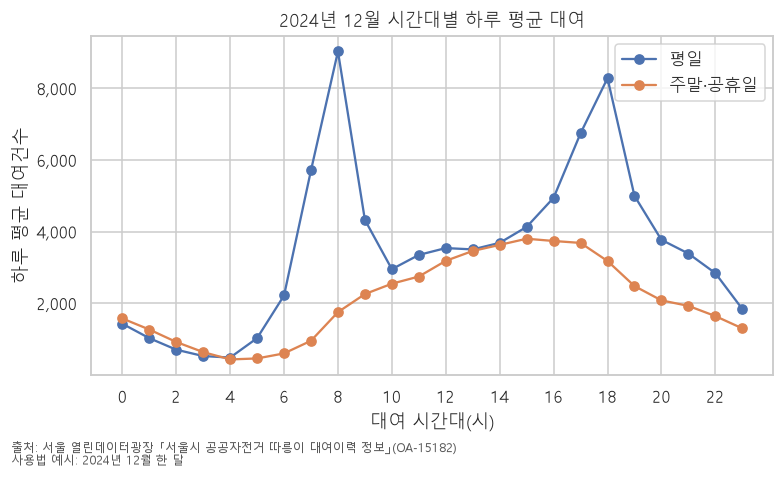

In [48]:
fig, ax = plt.subplots(figsize=(8, 4))
for kind, part in hourly.groupby("일구분", observed=True):
    ax.plot(part["시간대"], part["하루평균"], marker="o", label=kind)
ax.set(xlabel="대여 시간대(시)", ylabel="하루 평균 대여건수", title="2024년 12월 시간대별 하루 평균 대여")
ax.set_xticks(range(0, 24, 2))
viz.comma_axis(ax)
ax.legend()
viz.add_source(fig, "rent_history", note="사용법 예시: 2024년 12월 한 달")
# viz.save_fig(fig, "02_시간대별_하루평균")  # figures/02_시간대별_하루평균.png로 저장
plt.show()

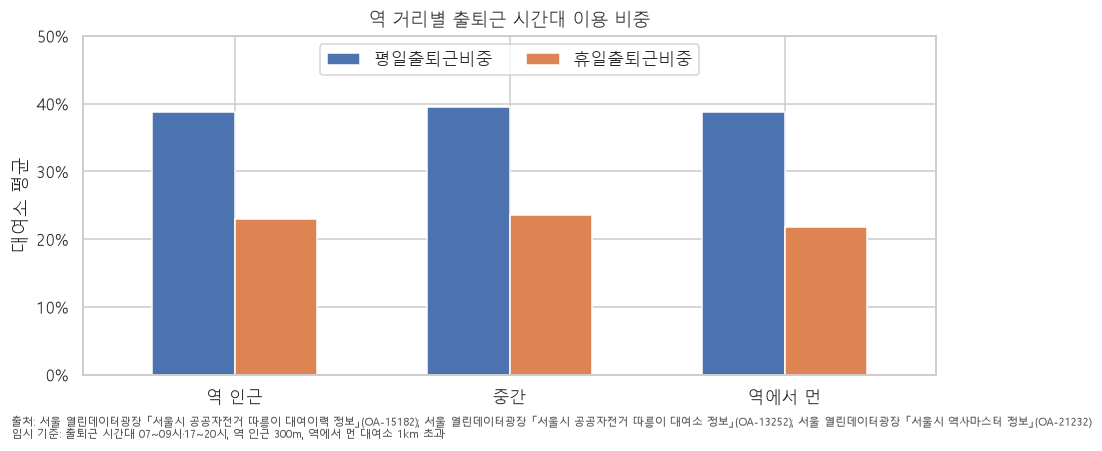

In [49]:
# 출처가 여러 개라 글이 길면 그림이 출처 폭만큼 넓어진다. figsize를 넓히거나 add_source(fontsize=7)로 줄인다
fig, ax = plt.subplots(figsize=(10, 4))
prox[["평일출퇴근비중", "휴일출퇴근비중"]].plot.bar(ax=ax, rot=0, width=0.6)
viz.percent_axis(ax)
ax.set_ylim(0, 0.5)
ax.legend(loc="upper center", ncol=2)
ax.set(xlabel="", ylabel="대여소 평균", title="역 거리별 출퇴근 시간대 이용 비중")
viz.add_source(
    fig, "rent_history", "stations", "subway_stations", note=config.provisional_note(), fontsize=7
)
plt.show()

In [50]:
viz.table_with_source(
    prox,
    "rent_history",
    "stations",
    "subway_stations",
    note=config.provisional_note(),
    precision=3,
)

,대여소수,평일출퇴근비중,휴일출퇴근비중,통근지수
역근접구분,,,,
역 인근,688,0.388,0.230,0.158
중간,898,0.395,0.235,0.163
역에서 먼,103,0.387,0.218,0.150


## 다음에 할 일

- 분석 노트북(`01`~`06`)에서는 1절의 첫 셀로 시작해 필요한 함수만 불러 씁니다.
- 반복 기준, 출퇴근 시간대, 역 반경 같은 값은 팀이 정하면 `src/config.py`(시간대·반경)나 노트북의 인자(반복 기준)로 바꿉니다. 노트북마다 숫자를 따로 적지 않습니다.
- 두 노트북 이상에서 같은 코드를 쓰게 되면 `src/`로 옮깁니다.